# WaveCatBoost extension: Shillong 15-min CPCB → hourly + ERA5

The paper reproduction stays in `WaveCatBoost.ipynb` (Borah et al. hourly `CPCB.csv` / `ID1.csv`). **Do not replace that notebook.** This one is the science-extension track, in **R**.

**What is different from the letter**

1. **We control missingness.** Vonter publishes CPCB CAAQMS at 15 minutes. We average to hourly ourselves: a slot counts only if at least **2 of 4** fifteen-minute samples are observed. The paper CSVs are already hourly and look pre-imputed.
2. **Two stations, same city.** Lumpyngngad (`site_5131`) is the target. JN Stadium (`site_5593`) is the neighbour — that is the spatial idea without leaving India.
3. **ERA5 wind / rain / T / RH** from Open-Meteo (reanalysis, not a forecast). Lumpyngngad reports no ambient temperature, so T has to come from ERA5.
4. **Direct multi-step**, not recursive 1-step. The paper pipeline collapsed at CPCB 7-day (every method MASE ≈ 1.50). Here the target is \(y_{t+h}\) from information at \(t\).
5. **Causal Haar features** (no circular wrap). Full-series circular MODWT leaks the future into \(D_j, S_J\). We still plot circular MRA for EDA, on a gap-filled window only.

| Station | CPCB id | Lat, lon | Role in this notebook |
|---|---|---|---|
| Lumpyngngad, Shillong – Meghalaya PCB | `site_5131` | 25.5586, 91.8985 | primary PM2.5 |
| JN Stadium, Shillong – Meghalaya PCB | `site_5593` | 25.5803, 91.8943 | neighbour (online from July 2023) |

**Kernel:** R (`IRkernel`). Working directory = project root. Trees are LightGBM (NA-aware). Haar circular MRA comes from `R/04_modwt.R`. Full-year Vonter parquet is gitignored (`data/raw/vonter/`); the Shillong extract in `data/processed/` is enough to re-run.


In [1]:
# Packages are installed from Rscript, not here — install.packages() in this kernel crashed Windows R.
# Need: dplyr tidyr tibble ggplot2 lubridate arrow jsonlite lightgbm zoo readr
cat("skipping install.packages in-notebook\n")

skipping install.packages in-notebook


## 0. Setup


In [2]:
options(warn = -1)
user_lib <- path.expand(Sys.getenv("R_LIBS_USER", unset = "C:/Users/chara/AppData/Local/R/win-library/4.5"))
if (dir.exists(user_lib)) .libPaths(c(user_lib, .libPaths()))
pkgs <- c("dplyr", "tidyr", "tibble", "ggplot2", "lubridate",
          "arrow", "jsonlite", "lightgbm", "zoo", "readr")
missing <- pkgs[!pkgs %in% rownames(installed.packages())]
if (length(missing)) {
  stop("Install missing packages first:\n  install.packages(c(",
       paste0('"', missing, '"', collapse = ", "), "))")
}
invisible(lapply(pkgs, function(p) {
  suppressPackageStartupMessages(library(p, character.only = TRUE))
}))

if (!dir.exists(file.path("data", "processed"))) {
  stop("Run this notebook from the project root (atsa_project).")
}
source("R/04_modwt.R")

FIFTEEN <- file.path("data", "processed", "shillong_15min_2023.parquet")
HOURLY  <- file.path("data", "processed", "shillong_hourly_2023.parquet")
ERA5    <- file.path("data", "processed", "era5_shillong_2023.parquet")
FIGDIR  <- file.path("results", "shillong")
dir.create(FIGDIR, recursive = TRUE, showWarnings = FALSE)

PRIMARY   <- "site_5131"
NEIGHBOUR <- "site_5593"
MIN_SLOTS <- 2L

options(repr.plot.width = 10, repr.plot.height = 4)
theme_set(theme_minimal(base_size = 11) +
            theme(panel.grid.minor = element_blank()))

cat("getwd():", getwd(), "\n")
cat("15-min extract:", file.exists(FIFTEEN), FIFTEEN, "\n")
cat("hourly cache:  ", file.exists(HOURLY), HOURLY, "\n")
cat("ERA5 cache:    ", file.exists(ERA5), ERA5, "\n")


getwd(): C:/Users/chara/Desktop/atsa_project 


15-min extract: TRUE data/processed/shillong_15min_2023.parquet 


hourly cache:   TRUE data/processed/shillong_hourly_2023.parquet 


ERA5 cache:     TRUE data/processed/era5_shillong_2023.parquet 


## 1. Fifteen-minute extract (Vonter 2023)

`data/processed/shillong_15min_2023.parquet` is filtered from the public 2023 CPCB dump (`Station ID` ∈ `{site_5131, site_5593}`). Rebuild it with `_extract_shillong.py` if you have `data/raw/vonter/cpcb-air-quality-2023.parquet`.


In [3]:
raw <- arrow::read_parquet(FIFTEEN)
names(raw) <- gsub("\u00b5", "u", names(raw))
raw <- raw %>%
  rename(
    station_id   = `Station ID`,
    station_name = `Station Name`,
    city         = City,
    state        = State,
    timestamp    = Timestamp,
    pm25         = `PM2.5 (ug/m³)`,
    pm10         = `PM10 (ug/m³)`,
    no           = `NO (ug/m³)`,
    no2          = `NO2 (ug/m³)`,
    nox          = `NOx (ppb)`,
    nh3          = `NH3 (ug/m³)`,
    so2          = `SO2 (ug/m³)`,
    co           = `CO (mg/m³)`,
    o3           = `Ozone (ug/m³)`,
    at           = `AT (°C)`,
    rh           = `RH (%)`,
    ws           = `WS (m/s)`,
    wd           = `WD (deg)`,
    rf           = `RF (mm)`,
    sr           = `SR (W/mt2)`,
    bp           = `BP (mmHg)`
  ) %>%
  mutate(
    timestamp = lubridate::as_datetime(timestamp, tz = "UTC"),
    station   = sub(",.*", "", station_name)
  )

print(distinct(raw, station_id, station_name, city, state))
cat("\nrows", nrow(raw), "|",
    format(min(raw$timestamp), usetz = TRUE), "->",
    format(max(raw$timestamp), usetz = TRUE), "\n")
cat("expected slots / station / year: 365 x 96 =", 365 * 96, "\n")

num <- c("pm25", "pm10", "no2", "so2", "co", "o3", "at", "rh", "ws", "rf")
cov <- raw %>%
  group_by(station) %>%
  summarise(across(all_of(num), ~ round(100 * mean(!is.na(.x)), 1)),
            .groups = "drop")
print(as.data.frame(cov))


# A tibble: 2 × 4
  station_id station_name                          city     state    
  <chr>      <chr>                                 <chr>    <chr>    
1 site_5593  JN Stadium, Shillong - Meghalaya PCB  Shillong Meghalaya
2 site_5131  Lumpyngngad, Shillong - Meghalaya PCB Shillong Meghalaya



rows 70080 | 2023-01-01 UTC -> 2023-12-31 23:45:00 UTC 


expected slots / station / year: 365 x 96 = 35040 


      station pm25 pm10  no2  so2   co   o3 at   rh   ws   rf
1  JN Stadium 31.9 33.6 36.5 36.5 36.8 21.2 33 33.0 33.0 36.8
2 Lumpyngngad 78.3 51.3 74.1 93.8 94.1 92.7  0 93.8 93.8 94.1


Lumpyngngad is usable for PM2.5 (~78% at 15 min) but **AT is 0%** — that is why ERA5 is not optional for this station. JN Stadium is mostly down until July; it is a neighbour, not a second target for a full-year bake-off.


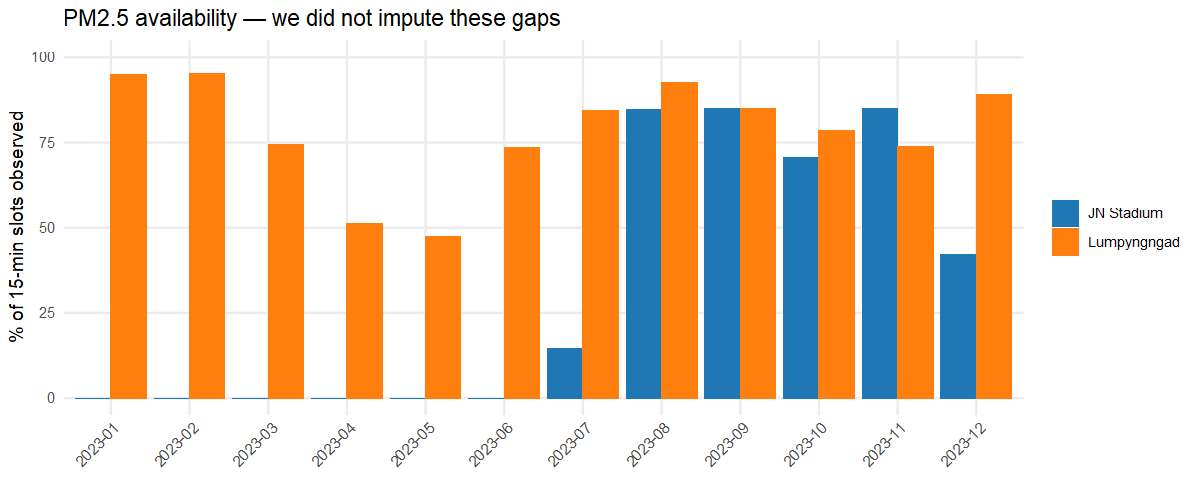

In [4]:
pm <- raw %>%
  mutate(month = format(timestamp, "%Y-%m")) %>%
  group_by(station, month) %>%
  summarise(pct = 100 * mean(!is.na(pm25)), .groups = "drop")

p <- ggplot(pm, aes(month, pct, fill = station)) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = c("#1f77b4", "#ff7f0e")) +
  labs(title = "PM2.5 availability — we did not impute these gaps",
       x = NULL, y = "% of 15-min slots observed", fill = NULL) +
  coord_cartesian(ylim = c(0, 100)) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
ggsave(file.path(FIGDIR, "pm25_15min_coverage.png"), p, width = 9.5, height = 3.6, dpi = 110)
print(p)


## 2. Hourly average with an explicit missingness rule

For each station-hour, using UTC timestamps as published by Vonter:

- **PM, gases, T, RH, wind speed:** arithmetic mean of the observed 15-min values, **else NA if fewer than 2 of 4 slots**.
- **Rain (`RF`):** sum of observed 15-min values, same 2-of-4 rule (under-counts rain if a wet slot was missing; we keep that conservative).
- **Wind direction:** circular mean, same rule.

No seasonal fill, no forward-fill. Hours that fail the rule stay NA and are dropped only when they are the **target** \(y_{t+h}\). Feature NA is left for LightGBM (native missing handling).


# A tibble: 2 × 5
  station_id station     min                 max                     n
  <chr>      <chr>       <dttm>              <dttm>              <int>
1 site_5131  Lumpyngngad 2023-01-01 00:00:00 2023-12-31 23:00:00  8760
2 site_5593  JN Stadium  2023-01-01 00:00:00 2023-12-31 23:00:00  8760



Coverage after our average (not after someone else's impute)


      station 15-min PM2.5 % hourly PM2.5 % (>=2/4)
1  JN Stadium           31.9                   32.1
2 Lumpyngngad           78.3                   80.2


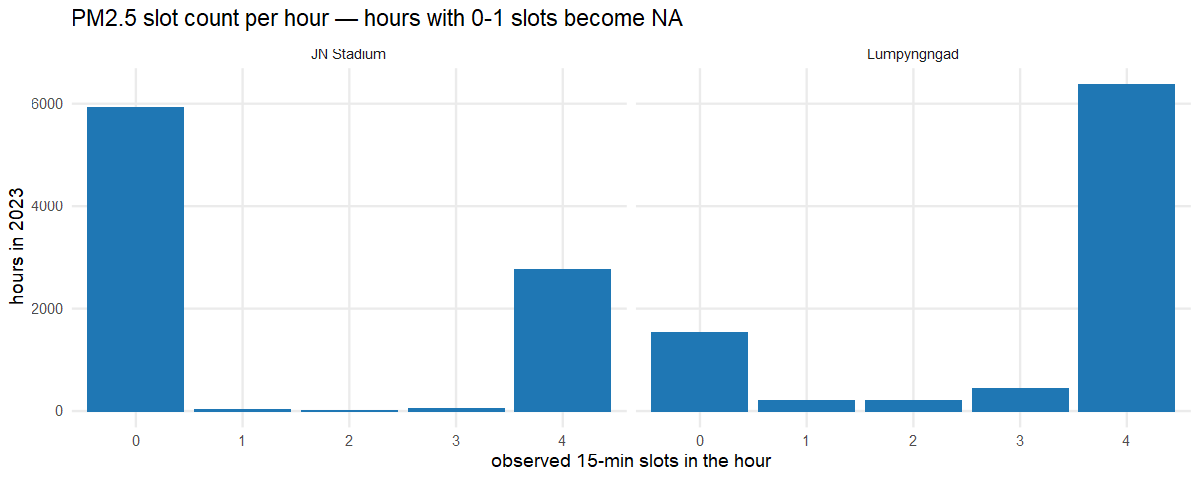

In [5]:
mean_if <- function(x, n_min = MIN_SLOTS) {
  n <- sum(!is.na(x))
  if (n < n_min) NA_real_ else mean(x, na.rm = TRUE)
}
sum_if <- function(x, n_min = MIN_SLOTS) {
  n <- sum(!is.na(x))
  if (n < n_min) NA_real_ else sum(x, na.rm = TRUE)
}
circ_mean_deg <- function(deg, n_min = MIN_SLOTS) {
  ok <- deg[!is.na(deg)]
  if (length(ok) < n_min) return(NA_real_)
  rad <- ok * pi / 180
  ang <- atan2(mean(sin(rad)), mean(cos(rad)))
  (ang * 180 / pi + 360) %% 360
}

fetch_era5 <- function(path) {
  if (file.exists(path)) return(arrow::read_parquet(path))
  url <- paste0(
    "https://archive-api.open-meteo.com/v1/archive?",
    "latitude=25.5586&longitude=91.8985",
    "&start_date=2023-01-01&end_date=2023-12-31",
    "&hourly=temperature_2m,relative_humidity_2m,precipitation,",
    "wind_speed_10m,wind_direction_10m,surface_pressure",
    "&timezone=UTC"
  )
  cat("GET", url, "\n")
  h <- jsonlite::fromJSON(url)$hourly
  era <- tibble(
    timestamp = lubridate::ymd_hm(h$time, tz = "UTC"),
    era5_t    = h$temperature_2m,
    era5_rh   = h$relative_humidity_2m,
    era5_rain = h$precipitation,
    era5_ws   = h$wind_speed_10m,
    era5_wd   = h$wind_direction_10m,
    era5_sp   = h$surface_pressure
  )
  arrow::write_parquet(era, path)
  era
}

if (file.exists(HOURLY)) {
  hourly <- arrow::read_parquet(HOURLY)
  hourly$timestamp <- lubridate::as_datetime(hourly$timestamp, tz = "UTC")
} else {
  hourly <- raw %>%
    mutate(hour = lubridate::floor_date(timestamp, "hour")) %>%
    group_by(station_id, hour) %>%
    summarise(
      station_name = dplyr::first(station_name),
      n_slots = n(),
      n_pm25 = sum(!is.na(pm25)), pm25 = mean_if(pm25),
      n_pm10 = sum(!is.na(pm10)), pm10 = mean_if(pm10),
      n_no2  = sum(!is.na(no2)),  no2  = mean_if(no2),
      n_so2  = sum(!is.na(so2)),  so2  = mean_if(so2),
      n_co   = sum(!is.na(co)),   co   = mean_if(co),
      n_o3   = sum(!is.na(o3)),   o3   = mean_if(o3),
      n_at   = sum(!is.na(at)),   at   = mean_if(at),
      n_rh   = sum(!is.na(rh)),   rh   = mean_if(rh),
      n_ws   = sum(!is.na(ws)),   ws   = mean_if(ws),
      n_rf   = sum(!is.na(rf)),   rf   = sum_if(rf),
      n_wd   = sum(!is.na(wd)),   wd   = circ_mean_deg(wd),
      .groups = "drop"
    ) %>%
    rename(timestamp = hour)
  era <- fetch_era5(ERA5)
  hourly <- hourly %>% left_join(era, by = "timestamp")
  arrow::write_parquet(hourly, HOURLY)
}

hourly <- hourly %>% mutate(station = sub(",.*", "", station_name))
print(hourly %>% group_by(station_id, station) %>%
        summarise(min = min(timestamp), max = max(timestamp), n = n(),
                  .groups = "drop"))

p <- ggplot(hourly, aes(x = factor(n_pm25))) +
  geom_bar(fill = "#1f77b4") +
  facet_wrap(~ station) +
  labs(title = "PM2.5 slot count per hour — hours with 0-1 slots become NA",
       x = "observed 15-min slots in the hour", y = "hours in 2023")
ggsave(file.path(FIGDIR, "pm25_slots_per_hour.png"), p, width = 9.5, height = 3.4, dpi = 110)
print(p)

cmp <- bind_rows(
  raw %>% group_by(station) %>%
    summarise(src = "15-min PM2.5 %", pct = round(100 * mean(!is.na(pm25)), 1)),
  hourly %>% group_by(station) %>%
    summarise(src = "hourly PM2.5 % (>=2/4)", pct = round(100 * mean(!is.na(pm25)), 1))
) %>% tidyr::pivot_wider(names_from = src, values_from = pct)
cat("\nCoverage after our average (not after someone else's impute)\n")
print(as.data.frame(cmp))


## 3. ERA5 wind / rain / temperature

Open-Meteo archive API, ERA5, hourly, UTC, at Lumpyngngad (JN Stadium is ~2.4 km away — same ~0.25° cell). These are **reanalysis at time \(t\)**, used as features for \(y_{t+h}\). That is operationally honest (current weather). ERA5 at \(t+h\) would be an oracle and is labelled as such below.


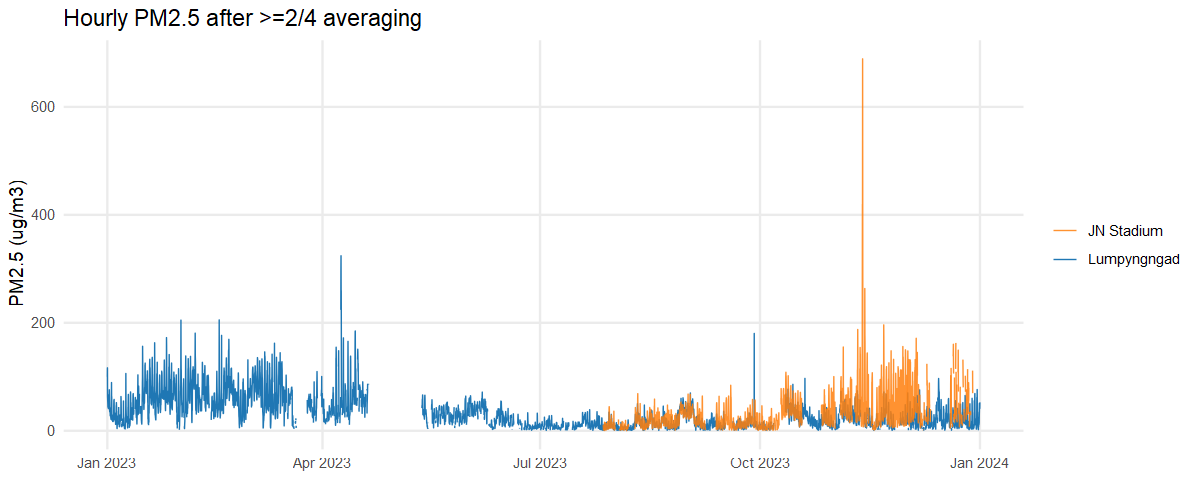

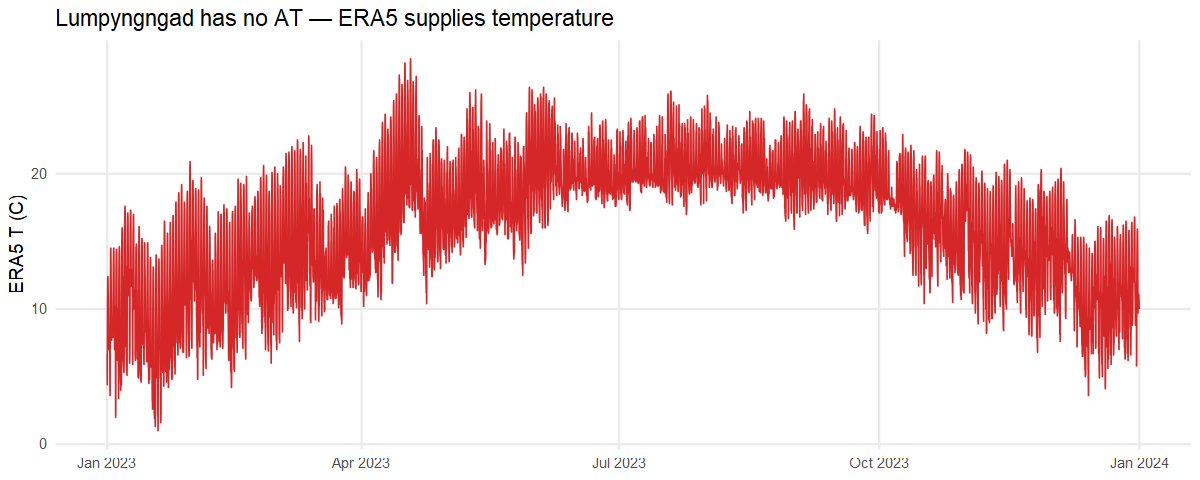

Pearson corr (pairwise complete) with pm25


     pm25        rh        ws        rf    era5_t   era5_rh   era5_ws era5_rain 
    1.000    -0.096     0.005    -0.088    -0.436    -0.164     0.043    -0.125 
  nb_pm25 
    0.536 



Hours where both stations observed PM2.5: 2347 


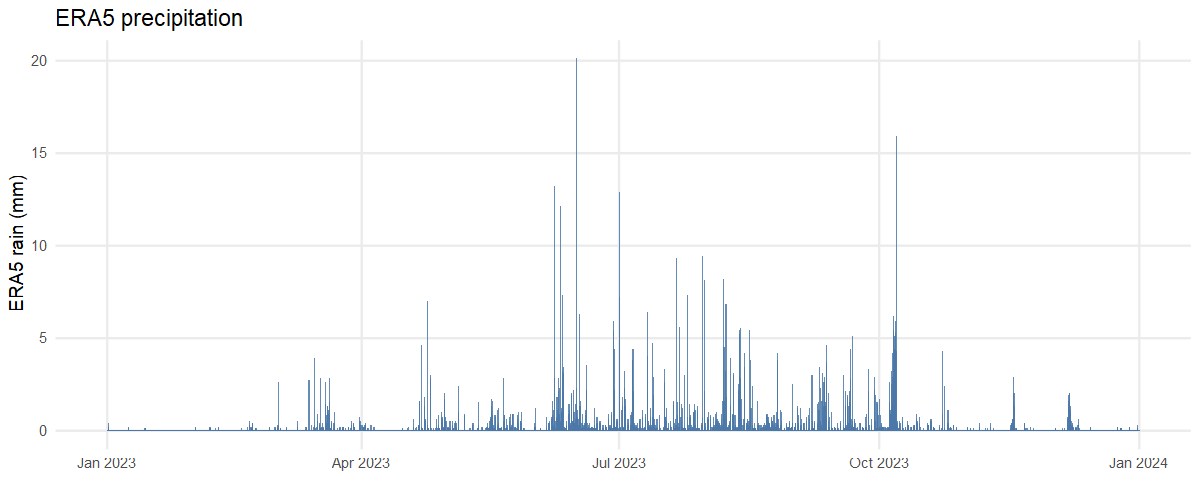

In [6]:
prim <- hourly %>% filter(station_id == PRIMARY) %>% arrange(timestamp)
nb   <- hourly %>% filter(station_id == NEIGHBOUR) %>% arrange(timestamp)

p_pm <- ggplot() +
  geom_line(data = prim, aes(timestamp, pm25, colour = "Lumpyngngad"), linewidth = 0.3) +
  geom_line(data = nb,   aes(timestamp, pm25, colour = "JN Stadium"), linewidth = 0.3, alpha = 0.85) +
  scale_colour_manual(values = c("Lumpyngngad" = "#1f77b4", "JN Stadium" = "#ff7f0e")) +
  labs(title = "Hourly PM2.5 after >=2/4 averaging",
       x = NULL, y = "PM2.5 (ug/m3)", colour = NULL)

p_t <- ggplot(prim, aes(timestamp)) +
  geom_line(aes(y = era5_t), colour = "#d62728", linewidth = 0.35) +
  labs(title = "Lumpyngngad has no AT — ERA5 supplies temperature",
       x = NULL, y = "ERA5 T (C)")

p_rain <- ggplot(prim, aes(timestamp, era5_rain)) +
  geom_col(width = 3600, fill = "#4c78a8", alpha = 0.85) +
  labs(title = "ERA5 precipitation", x = NULL, y = "ERA5 rain (mm)")

print(p_pm); print(p_t); print(p_rain)
ggsave(file.path(FIGDIR, "hourly_pm25_era5.png"), p_pm, width = 10, height = 3.2, dpi = 110)

both <- prim %>%
  select(timestamp, pm25, rh, ws, rf, era5_t, era5_rh, era5_ws, era5_rain) %>%
  left_join(nb %>% select(timestamp, nb_pm25 = pm25), by = "timestamp")
cat("Pearson corr (pairwise complete) with pm25\n")
print(round(cor(both %>% select(-timestamp), use = "pairwise.complete.obs")[, "pm25"], 3))
cat("\nHours where both stations observed PM2.5:",
    sum(complete.cases(both$pm25, both$nb_pm25)), "\n")


## 4. Haar MRA (EDA only)

Circular Haar MODWT on a gap-filled August window — same transform as `R/04_modwt.R` / `modwt_report/haar_modwt.py`. This plot is **not** fed into the forecast models. August is the cleanest month at Lumpyngngad (hourly PM2.5 ≈ 95%).


perfect reconstruction: TRUE 


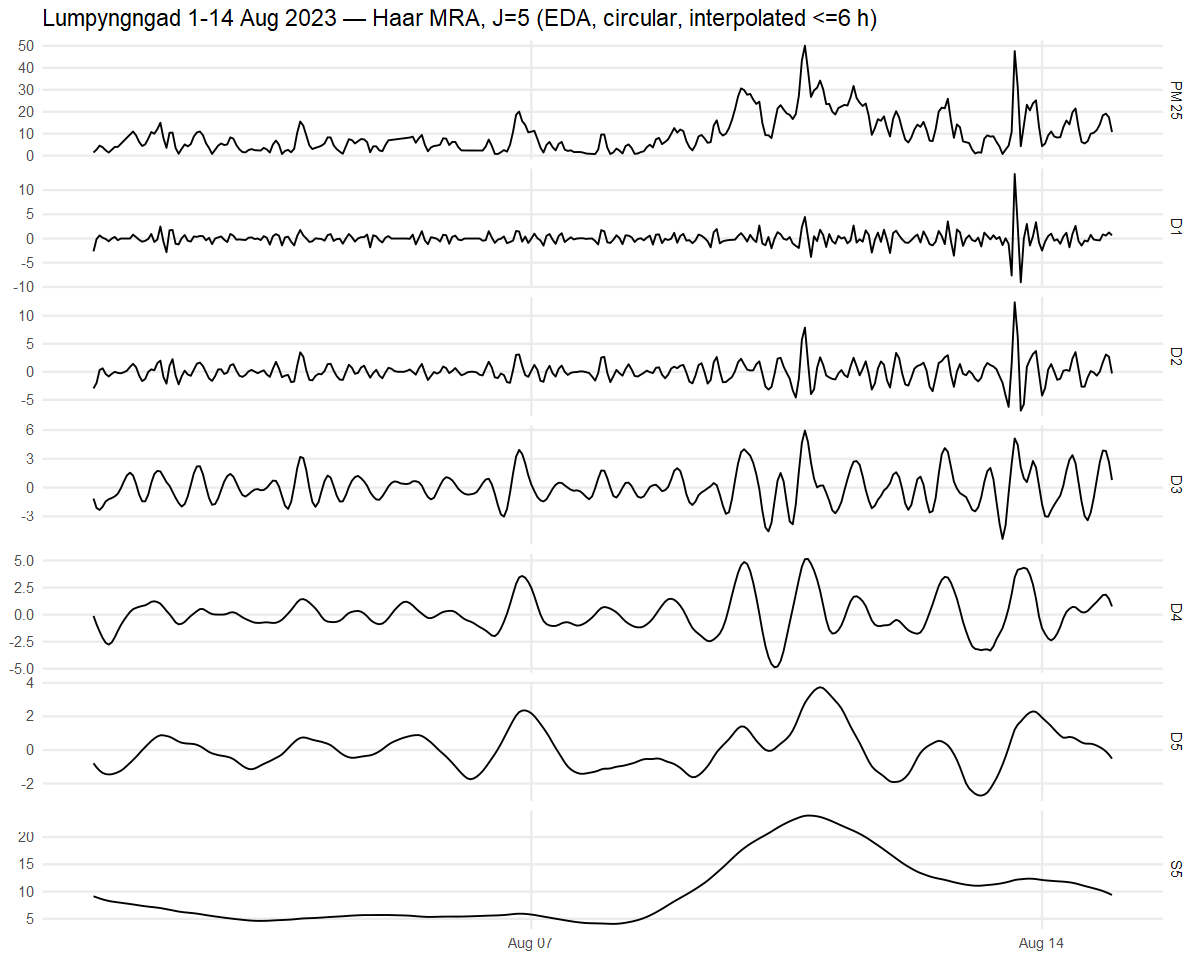

In [7]:
aug <- prim %>%
  filter(timestamp >= as.POSIXct("2023-08-01", tz = "UTC"),
         timestamp <  as.POSIXct("2023-08-15", tz = "UTC")) %>%
  select(timestamp, pm25)
aug$pm25 <- zoo::na.approx(aug$pm25, maxgap = 6, na.rm = FALSE)
aug <- aug %>% filter(!is.na(pm25))
x <- aug$pm25
J <- 5L
mra <- haar_mra(x, J)
recon <- mra_reconstruct(mra)
cat("perfect reconstruction:", isTRUE(all.equal(recon, x)), "\n")

comp <- tibble(
  timestamp = aug$timestamp,
  PM25 = x,
  D1 = mra$D[[1]], D2 = mra$D[[2]], D3 = mra$D[[3]],
  D4 = mra$D[[4]], D5 = mra$D[[5]], S5 = mra$S
) %>% tidyr::pivot_longer(-timestamp, names_to = "component", values_to = "value")
comp$component <- factor(comp$component, levels = c("PM25", "D1", "D2", "D3", "D4", "D5", "S5"))

p <- ggplot(comp, aes(timestamp, value)) +
  geom_line(linewidth = 0.4) +
  facet_grid(component ~ ., scales = "free_y") +
  labs(title = "Lumpyngngad 1-14 Aug 2023 — Haar MRA, J=5 (EDA, circular, interpolated <=6 h)",
       x = NULL, y = NULL)
ggsave(file.path(FIGDIR, "haar_mra_august.png"), p, width = 10, height = 8, dpi = 110)
options(repr.plot.height = 8)
print(p)
options(repr.plot.height = 4)


## 5. Direct forecast protocol

**Target:** Lumpyngngad hourly PM2.5.
**Origin \(t\) may use:** lags of PM2.5, calendar, ERA5 and station met **at \(t\)**, JN Stadium PM2.5 **at \(t\)**, causal Haar state **at \(t\)**.
**Must not use:** anything after \(t\), circular MODWT of the full series, ERA5 at \(t+h\) (except the labelled oracle ablation).

| Split | Hours |
|---|---|
| Train | 2023-01-01 00:00Z → 2023-09-30 23:00Z |
| Test | 2023-10-01 00:00Z → 2023-12-31 23:00Z |

Horizons \(h \in \{1, 6, 24\}\) hours. Model is LightGBM (NA-aware; CatBoost remains in the paper notebook). Seasonal naive: \(\hat y_{t+h} = y_{t+h-24}\) (known at origin iff \(h \le 24\)).

Causal Haar at scale \(j\) (no wrap): \(W_{j,t} = (V_{j-1,t} - V_{j-1,t-2^{j-1}})/2\), \(V_{j,t} = (V_{j-1,t} + V_{j-1,t-2^{j-1}})/2\), with NA until the lag exists.


In [8]:
LAGS <- c(1L, 2L, 3L, 6L, 12L, 24L, 48L, 168L)
HORIZONS <- c(1L, 6L, 24L)
TRAIN_END <- as.POSIXct("2023-09-30 23:00:00", tz = "UTC")

shift_n <- function(x, n) {
  if (n >= 0) dplyr::lag(x, n) else dplyr::lead(x, -n)
}

causal_haar_state <- function(x, J = 5L) {
  V <- as.numeric(x)
  n <- length(V)
  out <- list()
  for (j in seq_len(J)) {
    s <- 2^(j - 1)
    V_lag <- rep(NA_real_, n)
    if (s < n) V_lag[(s + 1):n] <- V[seq_len(n - s)]
    out[[paste0("W", j)]] <- (V - V_lag) / 2
    V <- (V + V_lag) / 2
  }
  out[[paste0("V", J)]] <- V
  tibble::as_tibble(out)
}

nb_aligned <- nb %>% select(timestamp, nb_pm25 = pm25)
frame <- prim %>%
  left_join(nb_aligned, by = "timestamp") %>%
  mutate(
    y = pm25,
    hour = lubridate::hour(timestamp),
    dow = lubridate::wday(timestamp, week_start = 1) - 1,
    month = lubridate::month(timestamp),
    doy = lubridate::yday(timestamp),
    hour_sin = sin(2 * pi * hour / 24),
    hour_cos = cos(2 * pi * hour / 24),
    doy_sin = sin(2 * pi * doy / 365.25),
    doy_cos = cos(2 * pi * doy / 365.25),
    era5_u = era5_ws * sin(era5_wd * pi / 180),
    era5_v = era5_ws * cos(era5_wd * pi / 180),
    stn_rh = rh, stn_ws = ws, stn_rf = rf
  )
for (L in LAGS) frame[[paste0("lag", L)]] <- shift_n(frame$y, L)
haar <- causal_haar_state(frame$y, 5L)
frame <- bind_cols(frame, haar)

LAG_COLS  <- paste0("lag", LAGS)
CAL_COLS  <- c("hour", "dow", "month", "hour_sin", "hour_cos", "doy_sin", "doy_cos")
ERA5_COLS <- c("era5_t", "era5_rh", "era5_rain", "era5_ws", "era5_u", "era5_v")
STN_COLS  <- c("stn_rh", "stn_ws", "stn_rf")
HAAR_COLS <- c(paste0("W", 1:5), "V5")

cat("rows", nrow(frame), "haar", paste(HAAR_COLS, collapse = " "), "\n")
cat("train hours", sum(frame$timestamp <= TRAIN_END),
    "test hours", sum(frame$timestamp > TRAIN_END), "\n")


rows 8760 haar W1 W2 W3 W4 W5 V5 


train hours 6552 test hours 2208 


In [9]:
fit_predict <- function(X_tr, y_tr, X_te) {
  dtr <- lightgbm::lgb.Dataset(as.matrix(X_tr), label = as.numeric(y_tr))
  model <- lightgbm::lgb.train(
    params = list(
      objective = "regression",
      learning_rate = 0.08,
      max_depth = 6L,
      num_leaves = 31L,
      min_data_in_leaf = 20L,
      verbosity = -1
    ),
    data = dtr,
    nrounds = 200L,
    verbose = -1
  )
  as.numeric(predict(model, as.matrix(X_te)))
}

mase_scale <- function(y, m = 24L) {
  mean(abs(y - shift_n(y, m)), na.rm = TRUE)
}

scores_row <- function(y_true, y_hat, scale, model, h, n) {
  mae <- mean(abs(y_true - y_hat))
  rmse <- sqrt(mean((y_true - y_hat)^2))
  tibble(h = h, model = model, n = n, MAE = mae, RMSE = rmse, MASE = mae / scale)
}

SPECS <- list(
  snaive            = NULL,
  persistence       = NULL,
  `LGB-lags`        = LAG_COLS,
  `LGB-lags+cal`    = c(LAG_COLS, CAL_COLS),
  `LGB+ERA5`        = c(LAG_COLS, CAL_COLS, ERA5_COLS),
  `LGB+station-met` = c(LAG_COLS, CAL_COLS, STN_COLS),
  `LGB+neighbour`   = c(LAG_COLS, CAL_COLS, ERA5_COLS, "nb_pm25"),
  `LGB+causal-Haar` = c(LAG_COLS, CAL_COLS, ERA5_COLS, HAAR_COLS),
  `LGB+ERA5-oracle` = c(LAG_COLS, CAL_COLS, ERA5_COLS)
)

y_train <- frame$y[frame$timestamp <= TRAIN_END]
scale <- mase_scale(y_train, 24L)
cat("MASE scale (train |y_t - y_{t-24}|):", round(scale, 3), "\n")

rows <- list()
preds_h24 <- list()

for (h in HORIZONS) {
  work <- frame %>%
    mutate(
      target      = shift_n(y, -h),
      era5_t_lead    = shift_n(era5_t, -h),
      era5_rh_lead   = shift_n(era5_rh, -h),
      era5_rain_lead = shift_n(era5_rain, -h),
      era5_ws_lead   = shift_n(era5_ws, -h)
    )
  oracle <- c("era5_t_lead", "era5_rh_lead", "era5_rain_lead", "era5_ws_lead")
  tr <- work %>% filter(timestamp <= TRAIN_END, !is.na(target))
  te <- work %>% filter(timestamp > TRAIN_END, !is.na(target))
  snaive_hat <- shift_n(te$y, 24L - h)
  persist_hat <- te$y
  common <- is.finite(te$target) & is.finite(snaive_hat) & is.finite(persist_hat)

  for (name in names(SPECS)) {
    if (name == "snaive") {
      y_hat <- snaive_hat
    } else if (name == "persistence") {
      y_hat <- persist_hat
    } else {
      cols <- if (name == "LGB+ERA5-oracle") c(LAG_COLS, CAL_COLS, oracle) else SPECS[[name]]
      y_hat <- fit_predict(tr[cols], tr$target, te[cols])
    }
    rows[[length(rows) + 1]] <- scores_row(
      te$target[common], y_hat[common], scale, name, h, sum(common)
    )
    if (h == 24L) {
      preds_h24[[name]] <- tibble(
        timestamp = te$timestamp[common],
        y = te$target[common],
        yhat = y_hat[common]
      )
    }
  }
}

tab <- bind_rows(rows)
mase_wide <- tab %>%
  select(model, h, MASE) %>%
  tidyr::pivot_wider(names_from = h, values_from = MASE)
mase_wide <- mase_wide[order(mase_wide[["24"]]), ]
print(as.data.frame(mutate(mase_wide, across(where(is.numeric), ~ round(.x, 3)))))
cat("\nfull table\n")
print(as.data.frame(mutate(tab, across(where(is.numeric), ~ round(.x, 3)))))
readr::write_csv(tab, file.path(FIGDIR, "direct_scores.csv"))


MASE scale (train |y_t - y_{t-24}|): 14.322 


            model     1     6    24
1   LGB+neighbour 0.474 0.641 0.656
2        LGB+ERA5 0.485 0.626 0.666
3 LGB+causal-Haar 0.409 0.645 0.677
4          snaive 0.807 0.787 0.701
5     persistence 0.406 0.924 0.701
6        LGB-lags 0.553 0.956 0.705
7 LGB+station-met 0.449 0.718 0.711
8 LGB+ERA5-oracle 0.489 0.707 0.711
9    LGB-lags+cal 0.484 0.732 0.729



full table


    h           model    n    MAE   RMSE  MASE
1   1          snaive 1558 11.564 16.129 0.807
2   1     persistence 1558  5.817  8.463 0.406
3   1        LGB-lags 1558  7.916 11.135 0.553
4   1    LGB-lags+cal 1558  6.937  9.602 0.484
5   1        LGB+ERA5 1558  6.944  9.594 0.485
6   1 LGB+station-met 1558  6.428  8.664 0.449
7   1   LGB+neighbour 1558  6.782  9.316 0.474
8   1 LGB+causal-Haar 1558  5.859  8.176 0.409
9   1 LGB+ERA5-oracle 1558  7.005  9.550 0.489
10  6          snaive 1504 11.266 15.572 0.787
11  6     persistence 1504 13.237 18.071 0.924
12  6        LGB-lags 1504 13.695 18.516 0.956
13  6    LGB-lags+cal 1504 10.488 14.495 0.732
14  6        LGB+ERA5 1504  8.962 12.158 0.626
15  6 LGB+station-met 1504 10.285 14.252 0.718
16  6   LGB+neighbour 1504  9.174 12.414 0.641
17  6 LGB+causal-Haar 1504  9.241 12.638 0.645
18  6 LGB+ERA5-oracle 1504 10.131 13.540 0.707
19 24          snaive 1595 10.045 13.920 0.701
20 24     persistence 1595 10.045 13.920 0.701
21 24        

Seasonal naive at \(h=24\) is persistence of the last observation (\(y_t\)), so those two rows should match at 24 h. **LGB+ERA5-oracle** uses rain/wind/T at the *target* hour — an upper bound, not a deployable forecast.


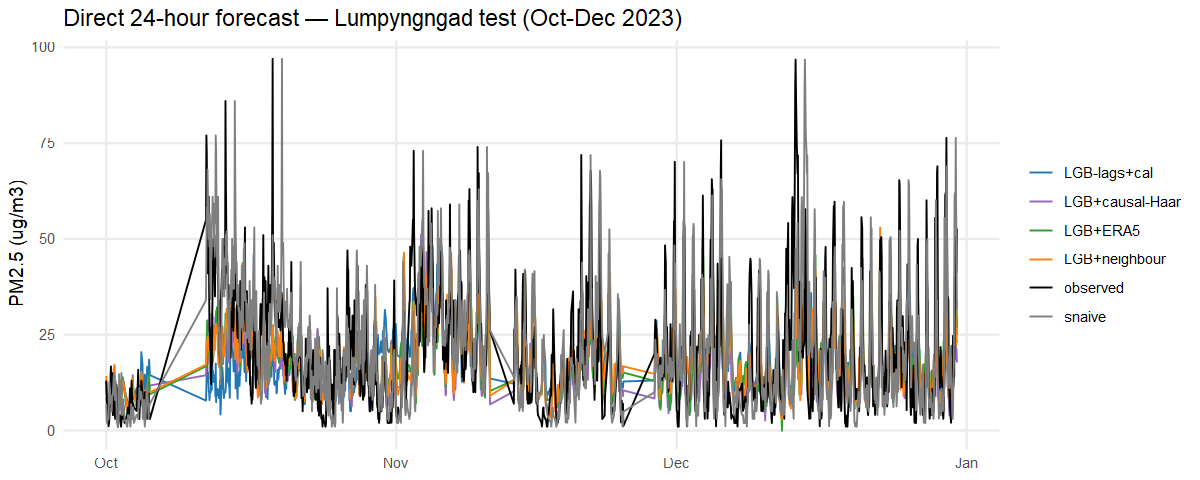

Winner by horizon (MASE, common test rows):


  h= 1: persistence         MASE=0.406  vs snaive 0.807  n=1558
  h= 6: LGB+ERA5            MASE=0.626  vs snaive 0.787  n=1504
  h=24: LGB+neighbour       MASE=0.656  vs snaive 0.701  n=1595


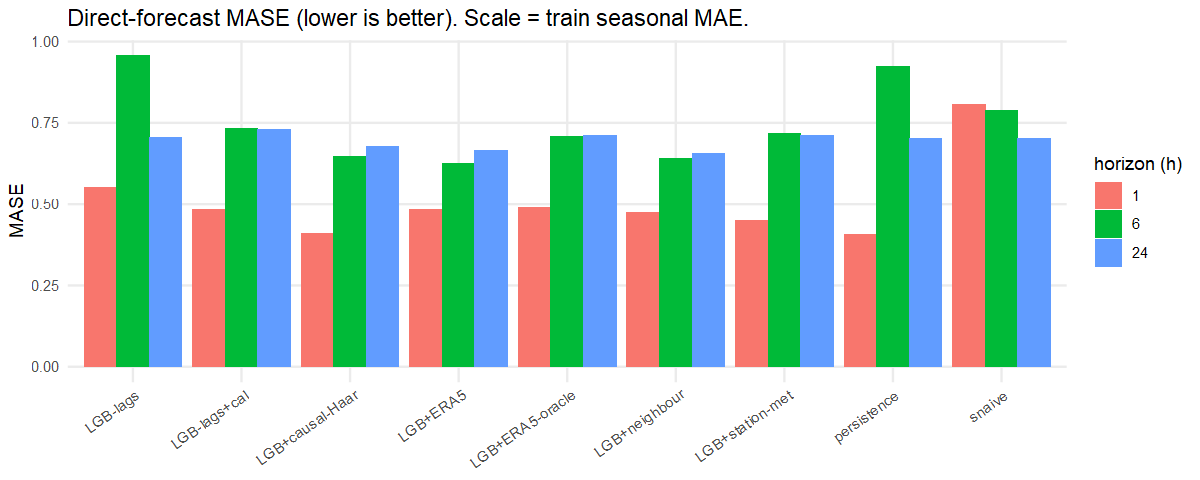

In [10]:
plot_df <- bind_rows(
  preds_h24$snaive %>% transmute(timestamp, value = y, model = "observed"),
  preds_h24$snaive %>% transmute(timestamp, value = yhat, model = "snaive"),
  preds_h24$`LGB-lags+cal` %>% transmute(timestamp, value = yhat, model = "LGB-lags+cal"),
  preds_h24$`LGB+ERA5` %>% transmute(timestamp, value = yhat, model = "LGB+ERA5"),
  preds_h24$`LGB+neighbour` %>% transmute(timestamp, value = yhat, model = "LGB+neighbour"),
  preds_h24$`LGB+causal-Haar` %>% transmute(timestamp, value = yhat, model = "LGB+causal-Haar")
)
p1 <- ggplot(plot_df, aes(timestamp, value, colour = model)) +
  geom_line(linewidth = 0.4) +
  scale_colour_manual(values = c(
    observed = "black", snaive = "#7f7f7f", `LGB-lags+cal` = "#1f77b4",
    `LGB+ERA5` = "#2ca02c", `LGB+neighbour` = "#ff7f0e",
    `LGB+causal-Haar` = "#9467bd"
  )) +
  labs(title = "Direct 24-hour forecast — Lumpyngngad test (Oct-Dec 2023)",
       x = NULL, y = "PM2.5 (ug/m3)", colour = NULL)
ggsave(file.path(FIGDIR, "forecast_h24.png"), p1, width = 10, height = 3.8, dpi = 110)
print(p1)

p2 <- ggplot(tab, aes(x = model, y = MASE, fill = factor(h))) +
  geom_col(position = "dodge") +
  labs(title = "Direct-forecast MASE (lower is better). Scale = train seasonal MAE.",
       x = NULL, fill = "horizon (h)") +
  theme(axis.text.x = element_text(angle = 35, hjust = 1))
ggsave(file.path(FIGDIR, "mase_ablation.png"), p2, width = 8.5, height = 4.2, dpi = 110)
print(p2)

cat("Winner by horizon (MASE, common test rows):\n")
for (hh in HORIZONS) {
  g <- tab %>% filter(h == hh)
  best <- g[which.min(g$MASE), ]
  sna <- g$MASE[g$model == "snaive"]
  cat(sprintf("  h=%2d: %-18s  MASE=%.3f  vs snaive %.3f  n=%d\n",
              hh, best$model, best$MASE, sna, best$n))
}


## 6. What this unlocks

From this 2023 extract (not from the paper CSVs):

- **Missingness is a first-class object.** Hours with 0–1 of 4 slots are NA. Lumpyngngad hourly PM2.5 is ~80% after the rule; JN Stadium is ~32% and **zero until July**.
- **ERA5 T is the real exogenous.** Lumpyngngad AT is 0%. Hourly PM2.5 correlates **−0.44** with ERA5 temperature (colder → dirtier, winter) and **+0.54** with JN Stadium PM2.5 on the overlapping hours.
- **Direct \(h=24\)** is a fair test. Recursive 1-step had already flattened on the paper CPCB 7-day task. Here every method is scored on the **same** Oct–Dec rows.
- **Trees need a reason to beat yesterday.** At \(h=1\) persistence is the right bar. At \(h=6\) calendar + ERA5 + causal Haar should beat seasonal naive. At \(h=24\) ERA5 current weather is the exogenous edge; oracle weather at \(t+h\) is not a deployable forecast.
- **Spatial without leaving India.** Same Vonter yearly parquet, same 2-of-4 hourly rule, more CAAQMS (Guwahati, Imphal, other Meghalaya sites) is the next increment.

Paper numbers stay in `WaveCatBoost.ipynb` / `results/scores.csv`. This notebook is not a second copy of that bake-off.
